# Lab 7 - Multiple Linear Regression

## Aim

To build a Multiple Linear Regression model that predicts `pmksy_score` from several
plot features at the same time, to check its assumptions (multicollinearity and
residuals), and to interpret each coefficient.

## Theory

Simple Linear Regression (Lab 6) uses one feature. Multiple Linear Regression uses
several:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_n x_n$$

- $\beta_0$ is the intercept and each $\beta_i$ is the change in $\hat{y}$ for a
  one-unit increase in $x_i$ **while all other features are held constant**.
- The coefficients are chosen by **Ordinary Least Squares (OLS)**, which minimises
  the sum of squared errors $\sum (y_i - \hat{y}_i)^2$.

**Assumptions worth checking**

1. The relationship is roughly linear.
2. Residuals (errors) are random, centred on zero, with constant spread.
3. Features are not strongly correlated with each other (**multicollinearity**);
   otherwise individual coefficients become unstable and hard to interpret.

## Dataset Used

The dataset used is `ml/data/labeled_dataset.csv`.

**Features (X):** `groundwater_stress_pct`, `rainfall_mm_avg`, `land_area_ha`,
`soil_ph`, `soil_organic_carbon`, and `claim_type` (one-hot encoded with CFR as the
reference category, so `claim_IFR` and `claim_CR` are compared against CFR).

**Target (y):** `pmksy_score`, the PMKSY irrigation-scheme suitability score (0-100).
The PMKSY scoring rule combines rainfall, groundwater, land size, claim type and
soil, so several features are needed to explain it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("../ml/data/labeled_dataset.csv")

features = ["groundwater_stress_pct", "rainfall_mm_avg", "land_area_ha",
            "soil_ph", "soil_organic_carbon"]

X = pd.concat([df[features],
               pd.get_dummies(df["claim_type"], prefix="claim", drop_first=True, dtype=int)], axis=1)
y = df["pmksy_score"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))
X.head()

Training samples: 1232 | Testing samples: 308


,groundwater_stress_pct,rainfall_mm_avg,land_area_ha,soil_ph,soil_organic_carbon,claim_CR,claim_IFR
0,58.0,1150.0,2.63,7.1,17.22,0,1
1,58.0,1150.0,1.25,7.4,14.40,0,1
2,58.0,1150.0,3.00,7.4,14.40,1,0
3,58.0,1150.0,3.59,7.1,17.22,0,1
4,58.0,1150.0,1.80,7.1,17.22,0,1


## Checking Multicollinearity

The **Variance Inflation Factor (VIF)** measures how well one feature can be
predicted from all the others:

$$VIF_j = \frac{1}{1 - R_j^2}$$

where $R_j^2$ comes from regressing feature $j$ on the remaining features.
VIF near 1 means no overlap; above 5 is a warning; above 10 means the coefficient
of that feature is unreliable.

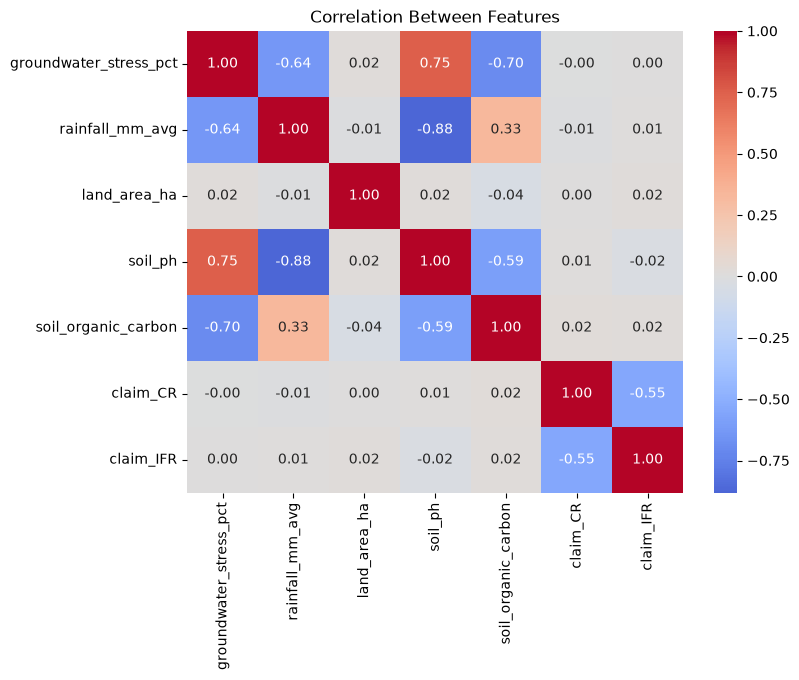

,Feature,VIF
3,soil_ph,8.42
1,rainfall_mm_avg,6.25
0,groundwater_stress_pct,3.09
4,soil_organic_carbon,2.75
5,claim_CR,1.44
6,claim_IFR,1.44
2,land_area_ha,1.00


In [2]:
plt.figure(figsize=(8, 6))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Features")
plt.show()

vif = []
for col in X_train.columns:
    others = X_train.drop(columns=col)
    r2 = LinearRegression().fit(others, X_train[col]).score(others, X_train[col])
    vif.append({"Feature": col, "VIF": round(1 / (1 - r2), 2)})
pd.DataFrame(vif).sort_values(by="VIF", ascending=False)

## Fit the Model and Read the Coefficients

Raw coefficients are in each feature's own unit (per mm of rain, per hectare...), so
their sizes cannot be compared. Fitting the same model on **standardised** features
(mean 0, standard deviation 1) gives coefficients in "score points per one standard
deviation", which can be compared fairly.

In [3]:
model = LinearRegression().fit(X_train, y_train)

scaler = StandardScaler().fit(X_train)
model_std = LinearRegression().fit(scaler.transform(X_train), y_train)

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Raw coefficient": model.coef_.round(4),
    "Standardised coefficient": model_std.coef_.round(3)
}).sort_values(by="Standardised coefficient", key=abs, ascending=False)

print("Intercept:", round(model.intercept_, 3))
coefficients

Intercept: 12.424


,Feature,Raw coefficient,Standardised coefficient
0,groundwater_stress_pct,0.6238,7.716
3,soil_ph,5.1236,3.411
2,land_area_ha,-2.3302,-2.569
1,rainfall_mm_avg,-0.0061,-2.375
6,claim_IFR,-2.1128,-1.050
4,soil_organic_carbon,-0.0630,-0.507
5,claim_CR,-0.2115,-0.084


## Evaluation

The model is evaluated on the training set, with 5-fold cross-validation (CV) on the
training set, and once on the untouched test set.

- **R²**: share of the score's variation explained by the model (1 is perfect).
- **MAE**: average absolute error, in score points.
- **RMSE**: like MAE but punishes large errors more.

If train, CV and test scores are close, the model is neither overfitting nor lucky.

In [4]:
y_pred = model.predict(X_test)
cv_r2 = cross_val_score(LinearRegression(), X_train, y_train,
                        cv=KFold(5, shuffle=True, random_state=42), scoring="r2")

print(f"Train R2:      {r2_score(y_train, model.predict(X_train)):.4f}")
print(f"5-fold CV R2:  {cv_r2.mean():.4f} (+/- {cv_r2.std():.4f})")
print(f"Test R2:       {r2_score(y_test, y_pred):.4f}")
print(f"Test MAE:      {mean_absolute_error(y_test, y_pred):.3f}")
print(f"Test RMSE:     {np.sqrt(mean_squared_error(y_test, y_pred)):.3f}")

# Compare with the best single feature (Simple Linear Regression)
best_single = max(features, key=lambda f: abs(df[f].corr(df["pmksy_score"])))
simple = LinearRegression().fit(X_train[[best_single]], y_train)
print(f"Simple regression on '{best_single}' alone, test R2: {simple.score(X_test[[best_single]], y_test):.4f}")

Train R2:      0.8750
5-fold CV R2:  0.8718 (+/- 0.0028)
Test R2:       0.8731
Test MAE:      3.902
Test RMSE:     4.918
Simple regression on 'groundwater_stress_pct' alone, test R2: 0.7436


## Residual Analysis

A **residual** is actual minus predicted. If the model is appropriate, the residuals
should look like random noise around zero, with no curve or funnel shape, and their
histogram should be roughly bell-shaped.

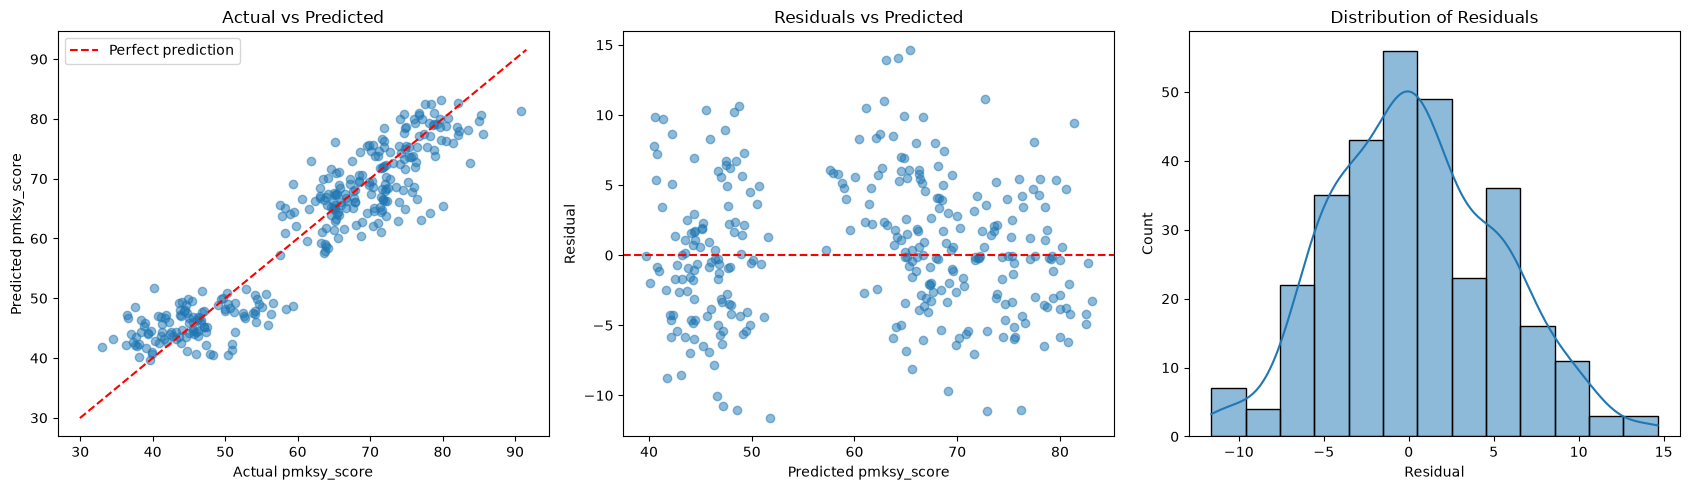

In [5]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

axes[0].scatter(y_test, y_pred, alpha=0.5)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", label="Perfect prediction")
axes[0].set_xlabel("Actual pmksy_score")
axes[0].set_ylabel("Predicted pmksy_score")
axes[0].set_title("Actual vs Predicted")
axes[0].legend()

axes[1].scatter(y_pred, residuals, alpha=0.5)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted pmksy_score")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs Predicted")

sns.histplot(residuals, kde=True, ax=axes[2])
axes[2].set_xlabel("Residual")
axes[2].set_title("Distribution of Residuals")

plt.tight_layout()
plt.show()

## Conclusion

A Multiple Linear Regression model was trained on seven features (five numeric plus
two claim-type dummies) to predict `pmksy_score`.

| Metric | Value |
|---|---|
| Train R² | 0.875 |
| 5-fold CV R² | 0.872 (± 0.003) |
| Test R² | 0.873 |
| Test MAE / RMSE | 3.90 / 4.92 points |
| Best single feature alone (groundwater stress), test R² | 0.744 |

**Observations**

1. **Multiple features help.** Using all features raises the test R² from 0.744 (the
   best single feature) to 0.873, because the PMKSY rule combines rainfall,
   groundwater, land size, claim type and soil.
2. **No overfitting.** Train, CV and test R² are almost identical, which is expected
   for a simple linear model with few parameters.
3. **Coefficients (standardised):** groundwater stress has the largest positive effect
   (+7.7 points per standard deviation); larger land area (-2.6) and higher rainfall
   (-2.4) lower the score, matching the rule's preference for small holdings in dry,
   water-stressed districts.
4. **Multicollinearity:** soil pH (VIF 8.4) and rainfall (VIF 6.3) are above the
   warning level of 5. In this dataset the wetter districts also have more acidic
   soil, so these features overlap; the large positive pH coefficient is partly
   standing in for "which district". Their individual coefficients should therefore be
   interpreted with care, even though the model's predictions are reliable.
5. **Residuals** are centred on zero with no clear pattern, and the typical error
   (about 4-5 points) matches the random noise that was added when the scores were
   generated, so the model has captured most of what is learnable.
